# KPI Mano de Obra – limpieza y EDA

**Trabajo Final Integrador – Herramientas básicas para el Análisis de Datos**
Autor: Lucas Doria

**Pregunta principal:** ¿cómo evolucionó el costo de la mano de obra (dotación, sueldos y horas extras) por línea de servicio entre enero y septiembre de 2026, y cuánto resultado operativo generó cada dólar pagado en mano de obra?

Subpreguntas:
- ¿Qué línea depende más de las horas extras?
- ¿El ratio RO / MO mejoró o empeoró en el año, y en qué líneas?

El caso es una empresa de servicios petroleros con 4 líneas de servicio (Fractura, SCBP, Well Testing y Wireline). Por confidencialidad **los datos son simulados**: respetan la estructura de los reportes reales (export de sueldos y P&L), pero los legajos, montos y tendencias no son los de la empresa.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

RAW = Path("../data/raw")
PROC = Path("../data/processed")
IMG = Path("../img")
PROC.mkdir(parents=True, exist_ok=True)
IMG.mkdir(parents=True, exist_ok=True)

## 1. Lectura de los datos

Son tres archivos:
- `nomina_liquidaciones_2026.csv`: export del sistema de sueldos. Una fila por legajo, mes y concepto liquidado (sueldo, contribuciones, horas extras 50% y 100%). Montos en pesos.
- `pl_lineas_2025_2026.csv`: P&L mensual en dólares (2025 completo y 2026 hasta septiembre), la hoja general y una por cada línea de servicio.
- `tipo_cambio_bcra_2026.csv`: tipo de cambio oficial de fin de mes (BCRA), para pasar la nómina a dólares.

In [2]:
nomina = pd.read_csv(RAW / "nomina_liquidaciones_2026.csv", sep=";", dtype={"importe": str})
pl = pd.read_csv(RAW / "pl_lineas_2025_2026.csv", sep=";")
tc = pd.read_csv(RAW / "tipo_cambio_bcra_2026.csv", sep=";")

print("nomina:", nomina.shape)
print("pl:", pl.shape)
nomina.head()

nomina: (10865, 10)
pl: (525, 6)


,id_liquidacion,legajo,periodo,departamento,grupo,convenio,fecha_ingreso,concepto,cantidad,importe
0,500001,2003,2026-01,OPERACIONES,fractura,Petroleros Convenio,17/11/2007,Sueldo y adicionales,30.00,5353819.8
1,500002,2003,2026-01,OPERACIONES,fractura,Petroleros Convenio,2007-11-17,Contribuciones patronales,NaN,1284916.75
2,500003,2003,2026-01,OPERACIONES,fractura,Petroleros Convenio,2007-11-17,Horas extras 50%,32.00,1343306.63
3,500004,2003,2026-01,OPERACIONES,fractura,Petroleros Convenio,2007-11-17,Horas extras 100%,10.00,575702.84
4,500005,2015,2026-01,OPERACIONES,fractura,Petroleros Jerárquicos,2020-01-21,Sueldo y adicionales,30.00,3309983.54


## 2. Auditoría: tipos, nulos, duplicados y valores raros

In [3]:
nomina.info()

<class 'pandas.DataFrame'>
RangeIndex: 10865 entries, 0 to 10864
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_liquidacion  10865 non-null  int64  
 1   legajo          10865 non-null  int64  
 2   periodo         10865 non-null  str    
 3   departamento    10865 non-null  str    
 4   grupo           9428 non-null   str    
 5   convenio        10865 non-null  str    
 6   fecha_ingreso   10865 non-null  str    
 7   concepto        10865 non-null  str    
 8   cantidad        7375 non-null   float64
 9   importe         10852 non-null  str    
dtypes: float64(1), int64(2), str(7)
memory usage: 849.0 KB


In [4]:
print("Nulos por columna:")
print(nomina.isna().sum())
print()
print("Filas duplicadas exactas:", nomina.duplicated().sum())
print("id_liquidacion repetidos:", nomina["id_liquidacion"].duplicated().sum())

Nulos por columna:
id_liquidacion       0
legajo               0
periodo              0
departamento         0
grupo             1437
convenio             0
fecha_ingreso        0
concepto             0
cantidad          3490
importe             13
dtype: int64

Filas duplicadas exactas: 86
id_liquidacion repetidos: 86


In [5]:
# como vienen escritos los departamentos y los grupos
print(nomina["departamento"].value_counts(dropna=False))
print()
print(nomina["grupo"].value_counts(dropna=False))

departamento
OPERACIONES          6321
MANTENIMIENTO         707
OPERACIONES           569
Operaciones           544
Logística             421
PRUEBA HIDRAULICA     382
ALMACEN               336
MAESTRANZA            245
ADMINISTRACION        184
CALIDAD               155
MASS                  142
COMPRAS               141
PLANIFICACION         129
RECURSOS HUMANOS      118
SISTEMAS               98
INTENDENCIA            98
Mantenimiento          65
MANTENIMIENTO          58
LOGISTICA              37
Logistica              35
Administracion         19
CALIDAD                15
ADMINISTRACION         14
Recursos Humanos       13
Calidad                12
RRHH                    7
Name: count, dtype: int64

grupo
fractura                  2504
SIN ASIGNAR               2088
SERVICIOS BOCA DE POZO    1738
WELL TEST                 1511
NaN                       1437
WL-SL                      637
WELL TESTING               276
Fractura                   232
FRACTURA                   222

In [6]:
# formatos de periodo e importe
print(nomina["periodo"].str.replace(r"\d", "9", regex=True).value_counts())
print()
print("Importes que no son numero:")
print(nomina.loc[pd.to_numeric(nomina["importe"], errors="coerce").isna() & nomina["importe"].notna(), "importe"].head())

periodo
9999-99    8988
99/9999    1228
ago-99       85
mar-99       80
sep-99       77
jun-99       74
abr-99       71
feb-99       68
may-99       68
ene-99       63
jul-99       63
Name: count, dtype: int64

Importes que no son numero:
11       $ 786.469,84
52     $ 1.683.348,13
232    $ 1.098.331,89
240    $ 1.777.596,23
273      $ 271.982,99
Name: importe, dtype: str


In [7]:
nomina.groupby("concepto")["cantidad"].describe()

,count,mean,std,min,25%,50%,75%,max
concepto,,,,,,,,
Contribuciones patronales,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Horas extras 100%,"1,936.00",18.09,55.93,0.50,8.00,11.50,19.50,999.00
Horas extras 50%,"1,946.00",29.37,66.88,1.50,18.50,25.50,32.00,999.00
Sueldo y adicionales,"3,493.00",29.77,1.68,12.00,30.00,30.00,30.00,30.00


**Qué encontré en la auditoría:**

- 10.865 filas y 10 columnas.
- `importe` lo tuve que leer como texto porque algunas filas vienen con formato `$ 1.234.567,89` y pandas no las toma como número.
- `periodo` viene en tres formatos distintos y `fecha_ingreso` en dos, las dos como texto.
- `departamento` tiene el mismo departamento escrito de varias formas (con espacio al final, con y sin tilde, mayúsculas/minúsculas, RRHH vs RECURSOS HUMANOS).
- `grupo` tiene nulos y también el texto `(en blanco)`. En los departamentos que no son de operaciones es normal que no tenga grupo, el problema es en OPERACIONES porque ahí el grupo define la línea.
- 86 filas duplicadas exactas (mismo id de liquidación): parece una doble exportación.
- 13 importes vacíos.
- `cantidad` vacía en contribuciones patronales es normal (ese concepto no tiene cantidad).
- En horas extras aparece un máximo de 999 hs, que no puede ser.

## 3. Limpieza

**3.1 Duplicados.** Son filas exactamente iguales (mismo `id_liquidacion`), así que se borran sin perder información.

In [8]:
antes = len(nomina)
nomina = nomina.drop_duplicates()
print(f"Se eliminaron {antes - len(nomina)} filas duplicadas. Quedan {len(nomina)}.")

Se eliminaron 86 filas duplicadas. Quedan 10779.


**3.2 Fechas.** El período viene como `2026-03`, `03/2026` o `mar-26`. Lo paso todo al primer día del mes. La fecha de ingreso viene en `aaaa-mm-dd` o `dd/mm/aaaa`.

In [9]:
MESES = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6,
         "jul": 7, "ago": 8, "sep": 9, "oct": 10, "nov": 11, "dic": 12}

def leer_periodo(p):
    p = str(p).strip().lower()
    if "/" in p:                      # 03/2026
        m, a = p.split("/")
    elif p[:3] in MESES:              # mar-26
        m, a = MESES[p[:3]], "20" + p.split("-")[1]
    else:                             # 2026-03
        a, m = p.split("-")
    return pd.Timestamp(int(a), int(m), 1)

nomina["mes"] = nomina["periodo"].apply(leer_periodo)

f1 = pd.to_datetime(nomina["fecha_ingreso"], format="%Y-%m-%d", errors="coerce")
f2 = pd.to_datetime(nomina["fecha_ingreso"], format="%d/%m/%Y", errors="coerce")
nomina["fecha_ingreso"] = f1.fillna(f2)

print(nomina["mes"].value_counts().sort_index())
print("Fechas de ingreso sin convertir:", nomina["fecha_ingreso"].isna().sum())

mes
2026-01-01    1136
2026-02-01    1155
2026-03-01    1182
2026-04-01    1193
2026-05-01    1216
2026-06-01    1216
2026-07-01    1207
2026-08-01    1244
2026-09-01    1230
Name: count, dtype: int64
Fechas de ingreso sin convertir: 0


**3.3 Importes.** Algunos vienen como texto con formato argentino (`$ 1.234.567,89`). Se sacan el signo $ y los puntos de miles y se cambia la coma decimal por punto.

In [10]:
def leer_importe(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if x.startswith("$"):
        x = x.replace("$", "").replace(".", "").replace(",", ".").strip()
    return float(x)

nomina["importe"] = nomina["importe"].apply(leer_importe)
print(nomina["importe"].describe())
print("Importes nulos:", nomina["importe"].isna().sum())

count       10,766.00
mean     2,539,792.50
std      2,391,066.67
min         13,402.84
25%        887,156.46
50%      1,455,174.64
75%      3,942,163.31
max     18,790,590.05
Name: importe, dtype: float64
Importes nulos: 13


**3.4 Categorías.** Departamento: saco espacios y tildes, paso a mayúsculas y unifico nombres distintos para lo mismo. Grupo: lo uso para asignar la línea de servicio (en el sistema la línea está en el grupo, no en el departamento).

In [11]:
def normalizar(t):
    if pd.isna(t):
        return np.nan
    t = unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode()
    return " ".join(t.upper().split())

nomina["departamento"] = nomina["departamento"].apply(normalizar).replace({"RECURSOS HUMANOS": "RRHH"})

nomina["grupo"] = nomina["grupo"].apply(normalizar).replace({"(EN BLANCO)": np.nan})
print(nomina["departamento"].value_counts())
print()
print(nomina["grupo"].value_counts(dropna=False))

departamento
OPERACIONES          7379
MANTENIMIENTO         823
LOGISTICA             486
PRUEBA HIDRAULICA     377
ALMACEN               333
MAESTRANZA            245
ADMINISTRACION        215
CALIDAD               181
MASS                  142
COMPRAS               139
RRHH                  137
PLANIFICACION         126
SISTEMAS               98
INTENDENCIA            98
Name: count, dtype: int64

grupo
FRACTURA                  2938
SIN ASIGNAR               2070
SERVICIOS BOCA DE POZO    1725
NaN                       1526
WELL TEST                 1502
WL-SL                      630
WELL TESTING               274
WL/SL                      114
Name: count, dtype: int64


Hay filas de OPERACIONES con el grupo vacío. Como cada legajo tiene varias filas (varios conceptos y meses), completo el grupo con el que tiene ese mismo legajo en el resto de sus filas.

In [12]:
grupo_legajo = (nomina.dropna(subset=["grupo"])
                      .groupby("legajo")["grupo"]
                      .agg(lambda s: s.mode()[0]))

ops = nomina["departamento"] == "OPERACIONES"
print("Operaciones sin grupo antes:", (ops & nomina["grupo"].isna()).sum())
nomina.loc[ops, "grupo"] = nomina.loc[ops, "grupo"].fillna(nomina.loc[ops, "legajo"].map(grupo_legajo))
print("Operaciones sin grupo después:", (ops & nomina["grupo"].isna()).sum())

LINEAS = {"FRACTURA": "Fractura", "SERVICIOS BOCA DE POZO": "SCBP",
          "WELL TEST": "WT", "WELL TESTING": "WT", "WL-SL": "Wireline", "WL/SL": "Wireline"}
nomina["linea"] = np.where(ops, nomina["grupo"].map(LINEAS), "Resto")
print(nomina["linea"].value_counts(dropna=False))

Operaciones sin grupo antes:

 196
Operaciones sin grupo después: 0
linea
Resto       3400
Fractura    3017
WT          1830
SCBP        1772
Wireline     760
Name: count, dtype: int64


**3.5 Importes nulos.** Son pocas filas y todas de contribuciones patronales. No las borro porque bajaría el costo de esa persona ese mes; las completo con la mediana de contribuciones del mismo legajo en los otros meses.

In [13]:
nulos = nomina["importe"].isna()
print("Nulos:", nulos.sum(), "-", nomina.loc[nulos, "concepto"].unique())
mediana = nomina.groupby(["legajo", "concepto"])["importe"].transform("median")
nomina["importe"] = nomina["importe"].fillna(mediana)
print("Quedan nulos:", nomina["importe"].isna().sum())

Nulos:

 13 - <StringArray>
['Contribuciones patronales']
Length: 1, dtype: str
Quedan nulos: 0


**3.6 Outliers en horas.** En el `describe()` de arriba el máximo de horas extras es 999. Eso es imposible: un mes tiene unas 720 horas en total. Tomo como error de carga todo lo que pase de 300 hs de un solo tipo de hora extra en el mes (serían 10 hs extra todos los días). Pongo esas horas en nulo y mantengo el importe, que es coherente con el resto.

In [14]:
es_he = nomina["concepto"].str.startswith("Horas extras")
print(nomina.loc[es_he, "cantidad"].describe())
raras = es_he & (nomina["cantidad"] > 300)
print("Registros con más de 300 hs extras:", raras.sum())
print(nomina.loc[raras, ["legajo", "mes", "concepto", "cantidad", "importe"]])
nomina.loc[raras, "cantidad"] = np.nan

count   3,855.00
mean       23.78
std        62.12
min         0.50
25%        10.00
50%        19.00
75%        28.50
max       999.00
Name: cantidad, dtype: float64
Registros con más de 300 hs extras: 15
       legajo        mes           concepto  cantidad      importe
127      2658 2026-01-01   Horas extras 50%    999.00   830,709.01
715      6257 2026-01-01  Horas extras 100%    999.00   981,043.80
1961     6835 2026-02-01   Horas extras 50%    999.00 1,540,395.65
2389     2346 2026-03-01  Horas extras 100%    999.00 1,223,690.84
2513     3009 2026-03-01   Horas extras 50%    999.00 1,548,810.00
3114     6622 2026-03-01  Horas extras 100%    999.00   305,293.72
4128     5546 2026-04-01   Horas extras 50%    999.00   484,886.34
5284     5067 2026-05-01   Horas extras 50%    999.00   925,886.89
5670     7349 2026-05-01  Horas extras 100%    999.00   211,095.01
5907     8935 2026-05-01   Horas extras 50%    999.00 1,733,351.52
6172     3291 2026-06-01   Horas extras 50%    999.00 1,1

**3.7 Unidades.** Paso los importes a dólares con el tipo de cambio de fin de cada mes (el P&L está en dólares, así se pueden comparar).

In [15]:
tc["mes"] = pd.to_datetime(tc["periodo"] + "-01")
nomina = nomina.merge(tc[["mes", "tipo_cambio_ars_usd"]], on="mes", how="left")
print("Filas sin tipo de cambio:", nomina["tipo_cambio_ars_usd"].isna().sum())
nomina["importe_usd"] = nomina["importe"] / nomina["tipo_cambio_ars_usd"]
es_he = nomina["concepto"].str.startswith("Horas extras")   # se recalcula porque el merge cambia el índice

Filas sin tipo de cambio: 0


**3.8 Tabla por empleado y mes.** Paso los conceptos a columnas para tener una fila por legajo y mes.

In [16]:
emp = nomina.pivot_table(index=["mes", "legajo", "departamento", "linea"],
                         columns="concepto", values="importe_usd", aggfunc="sum", fill_value=0).reset_index()
horas = nomina[es_he].pivot_table(index=["mes", "legajo"], columns="concepto", values="cantidad", aggfunc="sum")
horas.columns = [c + " hs" for c in horas.columns]
emp = emp.merge(horas.reset_index(), on=["mes", "legajo"], how="left")
emp.columns.name = None
emp = emp.rename(columns={"Sueldo y adicionales": "sueldo_usd", "Contribuciones patronales": "contrib_usd",
                          "Horas extras 50%": "he50_usd", "Horas extras 100%": "he100_usd",
                          "Horas extras 50% hs": "he50_hs", "Horas extras 100% hs": "he100_hs"})
emp["he_usd"] = emp["he50_usd"] + emp["he100_usd"]
emp["costo_usd"] = emp["sueldo_usd"] + emp["contrib_usd"] + emp["he_usd"]

print(emp.shape)
print("Legajos repetidos en un mismo mes:", emp.duplicated(["mes", "legajo"]).sum())
emp.head()

(3462, 12)
Legajos repetidos en un mismo mes: 0


,mes,legajo,departamento,linea,contrib_usd,he100_usd,he50_usd,sueldo_usd,he100_hs,he50_hs,he_usd,costo_usd
0,2026-01-01,2003,OPERACIONES,Fractura,887.99,397.86,928.34,"3,699.94",10.00,32.00,"1,326.20","5,914.13"
1,2026-01-01,2015,OPERACIONES,Fractura,549.00,0.00,0.00,"2,287.48",NaN,NaN,0.00,"2,836.48"
2,2026-01-01,2017,OPERACIONES,WT,887.28,769.90,940.99,"3,696.99",20.00,32.00,"1,710.90","6,295.16"
3,2026-01-01,2031,MANTENIMIENTO,Resto,543.52,0.00,0.00,"2,264.66",NaN,NaN,0.00,"2,808.17"
4,2026-01-01,2054,OPERACIONES,WT,"1,733.50","1,281.84","1,566.69","7,222.93",17.00,27.50,"2,848.53","11,804.97"


Chequeo de outliers en el costo mensual por persona (regla del rango intercuartil, por departamento):

In [17]:
def fuera_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s > q3 + 3 * (q3 - q1))

emp["outlier"] = emp.groupby("departamento")["costo_usd"].transform(fuera_iqr)
print("Casos:", emp["outlier"].sum())
emp[emp["outlier"]].groupby(["departamento", "mes"]).size()

Casos: 7


departamento   mes       
ALMACEN        2026-06-01    1
MANTENIMIENTO  2026-06-01    1
               2026-07-01    1
MASS           2026-06-01    1
OPERACIONES    2026-06-01    3
dtype: int64

Salen 7 casos y son de dos tipos:

- **Junio:** es el mes en que se paga el medio aguinaldo, así que el costo de esa persona ese mes es más alto. No es un error.
- **Un legajo de MANTENIMIENTO en julio:** cuesta más de 3 veces lo normal ese mes y en agosto vuelve a su nivel. Parece un pago extraordinario (un retroactivo o un bono). No lo pude confirmar, así que **lo dejo** porque es costo que se pagó.

No borro ninguno de estos registros.

**P&L.** Acá la limpieza es más corta: renombrar las hojas para que coincidan con los nombres de línea de la nómina (en el P&L SCBP figura como `SBDP` y WT como `WellTesting`) y armar la fecha a partir del nombre del mes. La mano de obra viene en negativo (es un costo), así que para los ratios le cambio el signo.

In [18]:
print(pl.isna().sum().sum(), "nulos /", pl.duplicated().sum(), "duplicados")
pl["linea"] = pl["hoja"].replace({"P&L 2026": "Total base", "P&L 2025": "Total base", "SBDP": "SCBP", "WellTesting": "WT"})
MESES_PL = {"ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6,
            "JULIO": 7, "AGOSTO": 8, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12}
pl["mes"] = pd.to_datetime(dict(year=pl["anio"], month=pl["mes"].str.strip().str.upper().map(MESES_PL), day=1))

plw = pl.pivot_table(index=["linea", "mes"], columns="concepto", values="valor_usd", aggfunc="sum").reset_index()
plw["ro"] = plw["Resultado Operativo"]
plw["mo"] = -(plw["Mano de Obra Directa"] + plw["Mano de Obra Indirecta"])
plw["ratio_ro_mo"] = plw["ro"] / plw["mo"]
plw26 = plw[plw["mes"].dt.year == 2026].copy()   # el análisis es 2026; 2025 se usa solo para comparar
print(plw.groupby(plw["mes"].dt.year).size())
plw26.head()

0 nulos / 0 duplicados


mes
2025    60
2026    45
dtype: int64


concepto,linea,mes,Costo Total,Mano de Obra Directa,Mano de Obra Indirecta,Margen Bruto,Resultado Operativo,ro,mo,ratio_ro_mo
12,Fractura,2026-01-01,"-1,652,312.62","-723,425.10","-80,813.13","2,418,192.26","4,070,504.89","4,070,504.89","804,238.23",5.06
13,Fractura,2026-02-01,"-1,513,402.07","-718,008.63","-68,206.72","2,479,132.23","3,992,534.30","3,992,534.30","786,215.35",5.08
14,Fractura,2026-03-01,"-1,565,421.09","-716,356.63","-72,994.42","1,884,943.12","3,450,364.21","3,450,364.21","789,351.05",4.37
15,Fractura,2026-04-01,"-1,301,355.34","-725,343.27","-77,867.87","1,765,009.78","3,066,365.12","3,066,365.12","803,211.14",3.82
16,Fractura,2026-05-01,"-1,381,737.60","-729,955.30","-79,524.59","2,028,286.55","3,410,024.15","3,410,024.15","809,479.89",4.21


## 4. Exploración y gráficos

In [19]:
ORDEN = ["Fractura", "SCBP", "WT", "Wireline", "Resto"]
COLORES = dict(zip(ORDEN, ["#1f4e79", "#2e86c1", "#48c9b0", "#f5b041", "#a6acaf"]))
emp["mes_txt"] = emp["mes"].dt.strftime("%m-%Y")

### Gráfico 1 – Dotación mensual por línea

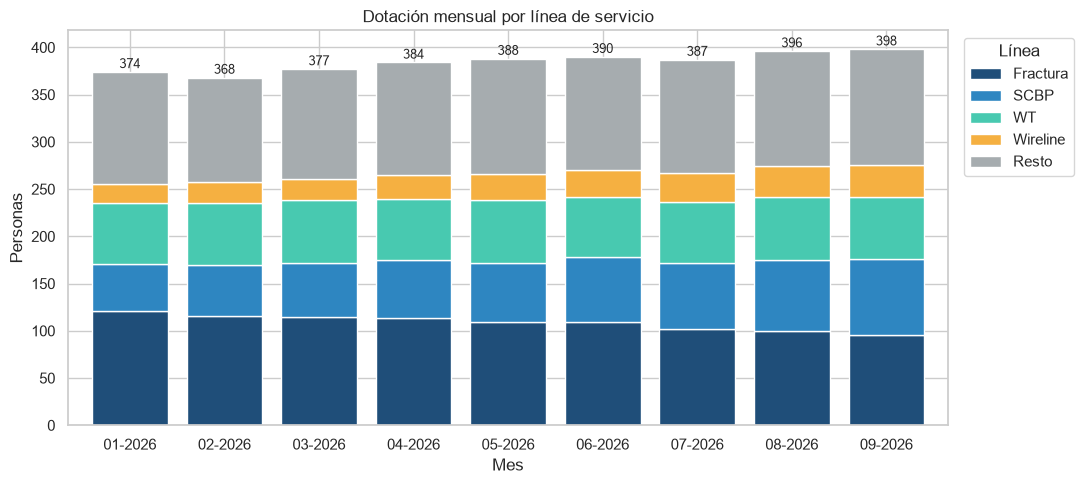

linea,Fractura,SCBP,WT,Wireline,Resto,Total
mes_txt,,,,,,
01-2026,121,50,64,20,119,374
02-2026,116,54,65,23,110,368
03-2026,115,57,66,23,116,377
04-2026,114,61,64,26,119,384
05-2026,109,63,66,28,122,388
06-2026,109,69,64,28,120,390
07-2026,102,70,64,31,120,387
08-2026,100,75,67,32,122,396
09-2026,96,80,66,34,122,398


In [20]:
dot = emp.groupby(["mes_txt", "linea"]).size().unstack()[ORDEN]
ax = dot.plot(kind="bar", stacked=True, figsize=(11, 5), color=[COLORES[l] for l in ORDEN], width=0.8)
for i, total in enumerate(dot.sum(axis=1)):
    ax.text(i, total + 4, int(total), ha="center", fontsize=9)
ax.set_title("Dotación mensual por línea de servicio")
ax.set_xlabel("Mes")
ax.set_ylabel("Personas")
plt.xticks(rotation=0)
plt.legend(title="Línea", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(IMG / "01_dotacion_por_linea.png", dpi=120)
plt.show()
dot.assign(Total=dot.sum(axis=1))

**Lectura:** la dotación total creció poco, de 374 personas en enero a 398 en septiembre (+6,4%), pero adentro hubo un cambio fuerte de composición. **Fractura** se achicó de 121 a 96 personas, mientras que **SCBP** pasó de 50 a 80 y **Wireline** de 20 a 34. WT y Resto se mantuvieron casi iguales. En septiembre Fractura sigue siendo la línea más grande, pero SCBP ya está cerca.

### Gráfico 2 – Costo laboral mensual por línea (USD)

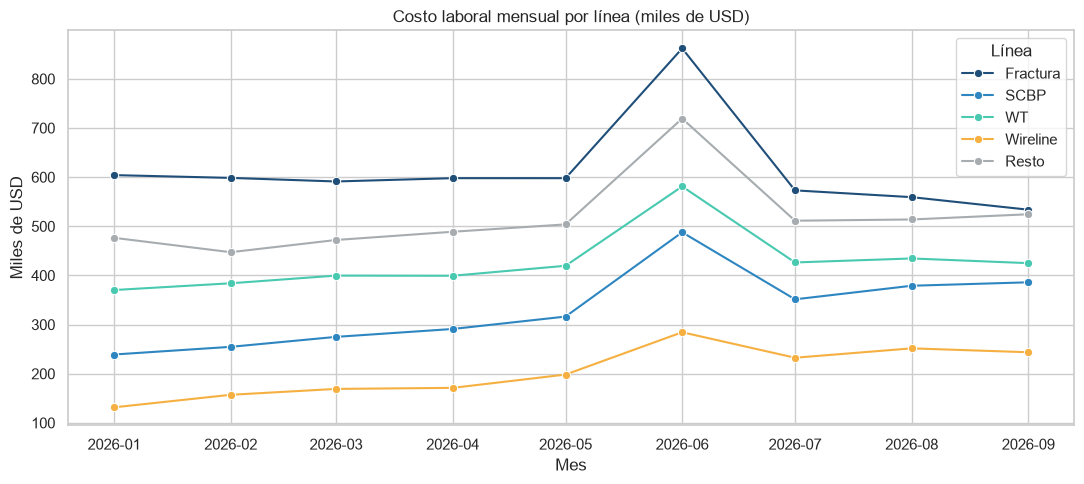

linea,Fractura,SCBP,WT,Wireline,Resto
mes,,,,,
2026-01-01,"604,133.00","239,064.00","370,255.00","131,568.00","476,516.00"
2026-02-01,"598,444.00","254,668.00","384,018.00","157,077.00","447,260.00"
2026-03-01,"591,190.00","274,941.00","399,655.00","169,038.00","472,123.00"
2026-04-01,"597,922.00","291,001.00","399,331.00","171,162.00","488,855.00"
2026-05-01,"597,875.00","316,247.00","419,601.00","198,238.00","503,821.00"
2026-06-01,"861,963.00","487,767.00","581,041.00","284,368.00","719,226.00"
2026-07-01,"573,074.00","351,341.00","426,379.00","232,477.00","511,324.00"
2026-08-01,"559,282.00","378,965.00","434,517.00","251,576.00","513,846.00"
2026-09-01,"533,764.00","385,990.00","424,967.00","243,649.00","524,444.00"


In [21]:
costo_mes = emp.groupby(["mes", "linea"])["costo_usd"].sum().reset_index()
plt.figure(figsize=(11, 5))
sns.lineplot(data=costo_mes, x="mes", y=costo_mes["costo_usd"] / 1e3, hue="linea",
             hue_order=ORDEN, palette=COLORES, marker="o")
plt.title("Costo laboral mensual por línea (miles de USD)")
plt.xlabel("Mes")
plt.ylabel("Miles de USD")
plt.legend(title="Línea")
plt.tight_layout()
plt.savefig(IMG / "02_costo_por_linea.png", dpi=120)
plt.show()
costo_mes.pivot(index="mes", columns="linea", values="costo_usd")[ORDEN].round(0)

**Lectura:** el salto de **junio** se ve en todas las líneas al mismo tiempo y es el medio aguinaldo, no un cambio en la operación. Sacando eso, el costo acompaña a la dotación: **Fractura** baja de unos 600 mil USD por mes a 534 mil en septiembre, y **SCBP** (+61%) y **Wireline** (+85%) son las que más suben. WT sube de a poco por los aumentos de sueldo, con la misma cantidad de gente.

### Gráfico 3 – Peso de las horas extras en el costo de cada línea

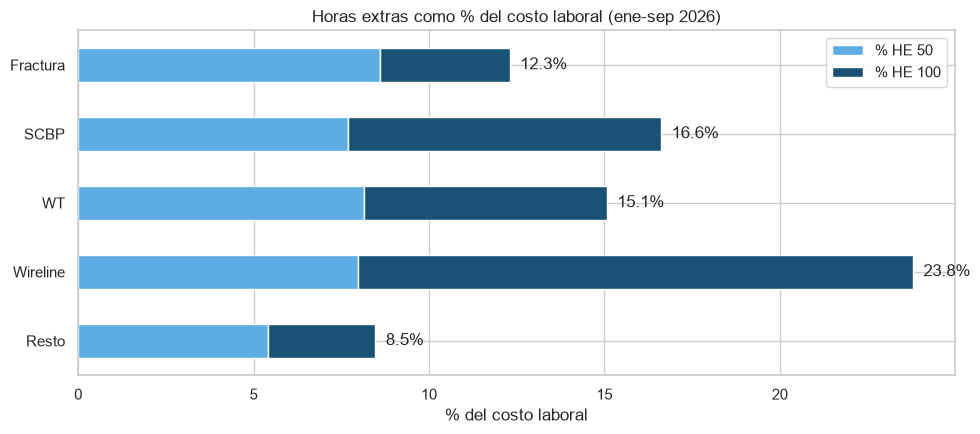

,he50_hs,he100_hs,% HE 50,% HE 100
linea,,,,
Fractura,"15,667.50","5,100.00",8.60,3.70
SCBP,"8,656.50","7,462.00",7.69,8.93
WT,"9,070.00","5,837.50",8.15,6.92
Wireline,"4,279.00","6,152.50",7.99,15.80
Resto,"10,151.00","4,325.00",5.40,3.07


In [22]:
he = emp.groupby("linea")[["he50_usd", "he100_usd", "costo_usd", "he50_hs", "he100_hs"]].sum().loc[ORDEN]
he["% HE 50"] = he["he50_usd"] / he["costo_usd"] * 100
he["% HE 100"] = he["he100_usd"] / he["costo_usd"] * 100

ax = he[["% HE 50", "% HE 100"]].plot(kind="barh", stacked=True, figsize=(10, 4.5), color=["#5dade2", "#1a5276"])
for i, v in enumerate(he["% HE 50"] + he["% HE 100"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.invert_yaxis()
ax.set_title("Horas extras como % del costo laboral (ene-sep 2026)")
ax.set_xlabel("% del costo laboral")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG / "03_peso_horas_extras.png", dpi=120)
plt.show()
he[["he50_hs", "he100_hs", "% HE 50", "% HE 100"]]

**Lectura:** en el total las horas extras son el 13,7% del costo laboral, pero cambia mucho según la línea. **Wireline** es la más dependiente (23,8%), y casi todo es hora al 100%, que es la más cara. En SCBP también pesa más la hora al 100%. **Fractura** usa menos horas extras (12,3%) y en su mayoría son al 50%. En Resto (soporte y administración) son poco más del 8%.

### Gráfico 4 – Distribución del costo mensual por persona

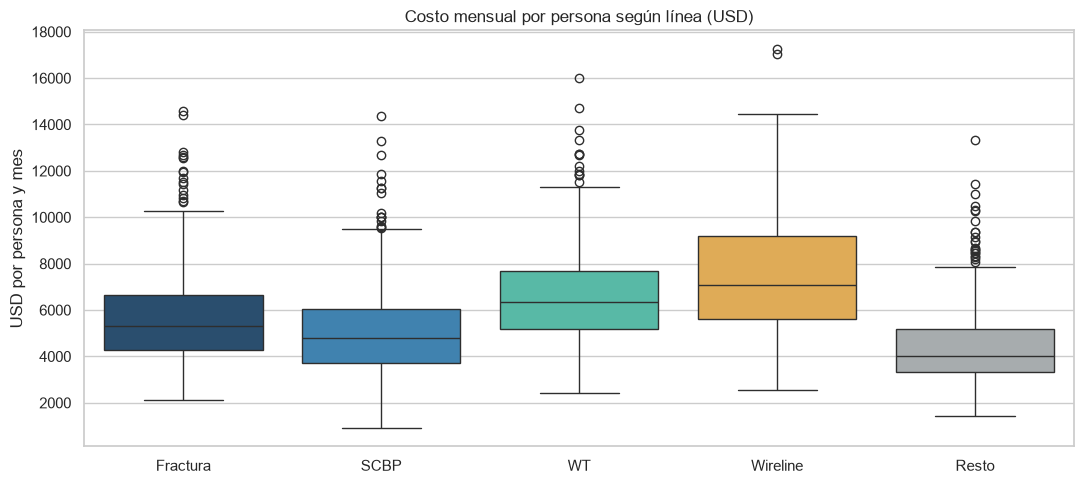

,count,mean,50%,max
linea,,,,
Fractura,982.00,"5,618.79","5,312.00","14,570.65"
SCBP,579.00,"5,146.78","4,795.77","14,384.55"
WT,586.00,"6,552.50","6,342.14","16,003.47"
Wireline,245.00,"7,506.75","7,064.31","17,239.19"
Resto,"1,070.00","4,352.72","4,032.42","13,313.78"


In [23]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=emp, x="linea", y="costo_usd", order=ORDEN, hue="linea", palette=COLORES, legend=False)
plt.title("Costo mensual por persona según línea (USD)")
plt.xlabel("")
plt.ylabel("USD por persona y mes")
plt.tight_layout()
plt.savefig(IMG / "04_costo_por_persona.png", dpi=120)
plt.show()
emp.groupby("linea")["costo_usd"].describe().loc[ORDEN][["count", "mean", "50%", "max"]]

**Lectura:** Wireline tiene el costo por persona más alto (mediana de unos USD 7.000 por mes), seguido por WT (6.300). SCBP y Fractura quedan alrededor de 4.800-5.300 y Resto es la más baja. Los puntos de arriba son casi todos de junio por el aguinaldo. O sea que Wireline es cara por persona y además depende mucho de las horas extras, por eso su costo creció más rápido que su dotación.

### Gráfico 5 – Ratio RO / MO (cuántos USD de resultado operativo por cada USD de mano de obra)

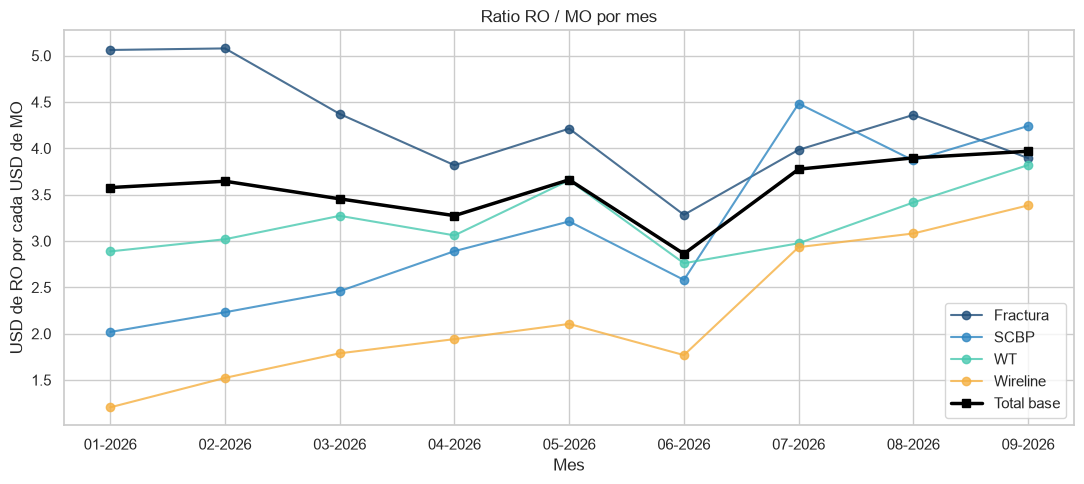

linea,Fractura,SCBP,Total base,WT,Wireline
mes_txt,,,,,
01-2026,5.06,2.02,3.58,2.89,1.21
02-2026,5.08,2.23,3.65,3.02,1.52
03-2026,4.37,2.46,3.45,3.27,1.79
04-2026,3.82,2.89,3.27,3.06,1.94
05-2026,4.21,3.21,3.66,3.66,2.11
06-2026,3.28,2.58,2.86,2.76,1.77
07-2026,3.98,4.48,3.78,2.98,2.93
08-2026,4.36,3.87,3.90,3.42,3.08
09-2026,3.89,4.24,3.97,3.82,3.38


In [24]:
plw26["mes_txt"] = plw26["mes"].dt.strftime("%m-%Y")
fig, ax = plt.subplots(figsize=(11, 5))
for l in ["Fractura", "SCBP", "WT", "Wireline"]:
    d = plw26[plw26["linea"] == l]
    ax.plot(d["mes_txt"], d["ratio_ro_mo"], marker="o", label=l, color=COLORES[l], alpha=0.8)
d = plw26[plw26["linea"] == "Total base"]
ax.plot(d["mes_txt"], d["ratio_ro_mo"], marker="s", label="Total base", color="black", linewidth=2.5)
ax.set_title("Ratio RO / MO por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("USD de RO por cada USD de MO")
ax.legend()
plt.tight_layout()
plt.savefig(IMG / "05_ratio_ro_mo.png", dpi=120)
plt.show()
plw26.pivot(index="mes_txt", columns="linea", values="ratio_ro_mo").round(2)

**Lectura:** el ratio total arrancó en 3,6 en enero, se movió entre 3,3 y 3,7 hasta mayo, cayó a 2,86 en junio (aguinaldo: más MO con el mismo RO) y después subió hasta casi 4,0 en septiembre. Las líneas van en direcciones distintas: **Fractura** es la que más rinde al principio, pero baja de 5,1 a 3,9. **SCBP** mejora muchísimo (de 2,0 a 4,2) y desde julio está a la par o por encima de Fractura. **Wireline** también mejora (de 1,2 a 3,4), aunque sigue siendo la más baja, y **WT** sube en el tercer trimestre.

## 5. KPIs

Defino tres KPIs. Para un período (un trimestre, ene-sep) siempre se calcula **suma del numerador / suma del denominador**, no el promedio de los valores mensuales, para que cada mes pese según su monto.

| KPI | Fórmula | Fuente |
|---|---|---|
| Ratio RO / MO | Resultado Operativo / (MO directa + MO indirecta) | P&L |
| % HE sobre costo laboral | (HE 50% + HE 100%) / costo laboral | Nómina |
| Costo laboral por persona | costo laboral / dotación | Nómina |

In [25]:
tot = plw26[plw26["linea"] == "Total base"]
kpi_ratio = tot["ro"].sum() / tot["mo"].sum()
t25 = plw[(plw["linea"] == "Total base") & (plw["mes"].dt.year == 2025) & (plw["mes"].dt.month <= 9)]
print(f"Ratio RO / MO ene-sep 2025: {t25['ro'].sum() / t25['mo'].sum():.2f}  (mismo período del año anterior)")
kpi_he = emp["he_usd"].sum() / emp["costo_usd"].sum() * 100
kpi_costo_pp = emp["costo_usd"].sum() / len(emp)

print(f"Ratio RO / MO ene-sep 2026: {kpi_ratio:.2f}")
print(f"% HE sobre costo laboral:    {kpi_he:.1f}%")
print(f"Costo laboral por persona:   USD {kpi_costo_pp:,.0f} por mes")

trim = tot.assign(trim=tot["mes"].dt.quarter).groupby("trim")[["ro", "mo"]].sum()
trim["ratio"] = trim["ro"] / trim["mo"]
trim

Ratio RO / MO ene-sep 2025: 3.32  (mismo período del año anterior)
Ratio RO / MO ene-sep 2026: 3.54
% HE sobre costo laboral:    13.7%
Costo laboral por persona:   USD 5,440 por mes


concepto,ro,mo,ratio
trim,,,
1,"19,813,979.93","5,569,596.37",3.56
2,"22,226,069.46","6,918,410.79",3.21
3,"24,588,574.86","6,336,105.02",3.88


**Lectura:** en el acumulado enero-septiembre cada dólar de mano de obra generó 3,54 dólares de resultado operativo, un poco más que en el mismo período de 2025 (3,32). Por trimestre: 3,56 en el T1, 3,21 en el T2 (por el aguinaldo de junio) y 3,88 en el T3, que es el mejor del año. Las horas extras son el 13,7% del costo laboral y el costo promedio es de unos USD 5.400 por persona por mes.

## 6. Exportar para Power BI

Guardo dos tablas en `data/processed/` con el mismo formato que usa el modelo de Power BI:
- `costo_salarial_mensual.csv`: una fila por departamento/línea y mes, con dotación, salarios, costo laboral y horas extras (en ARS, USD y horas).
- `pl_mensual.csv`: P&L en formato largo (línea, concepto, mes, escenario, valor).

In [26]:
nomina["concepto_bi"] = nomina["concepto"].replace({"Sueldo y adicionales": "Sueldo", "Contribuciones patronales": "Contribuciones"})
grp = ["mes", "departamento", "linea"]
cs = nomina.pivot_table(index=grp, columns="concepto_bi", values=["importe", "importe_usd"], aggfunc="sum", fill_value=0)
cs.columns = [f"{c}|{v}" for v, c in cs.columns]
cs = cs.reset_index()
hs = nomina[es_he].pivot_table(index=grp, columns="concepto", values="cantidad", aggfunc="sum", fill_value=0).reset_index()
dot_dep = emp.groupby(grp).size().rename("Dotación").reset_index()
cs = cs.merge(hs, on=grp, how="left").merge(dot_dep, on=grp, how="left")
cs[["Horas extras 50%", "Horas extras 100%"]] = cs[["Horas extras 50%", "Horas extras 100%"]].fillna(0)   # deptos sin horas extras

he50a, he100a = cs["Horas extras 50%|importe"], cs["Horas extras 100%|importe"]
he50u, he100u = cs["Horas extras 50%|importe_usd"], cs["Horas extras 100%|importe_usd"]
MES_NOMBRE = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]

bi = pd.DataFrame({
    "Mes": cs["mes"].dt.date,
    "Nombre del mes": cs["mes"].dt.month.map(lambda m: MES_NOMBRE[m - 1]),
    "N° de mes": cs["mes"].dt.month,
    "Departamento": np.where(cs["linea"] == "Resto", cs["departamento"],
                             cs["linea"].map({"Fractura": "FRACTURA", "SCBP": "SCBP", "WT": "WELL TESTING", "Wireline": "WIRELINE"})),
    "Línea de servicio": cs["linea"],
    "Orden línea": cs["linea"].map({l: i + 1 for i, l in enumerate(ORDEN)}),
    "Dotación": cs["Dotación"],
    "Salarios": (cs["Sueldo|importe"] + he50a + he100a).round(2),
    "Salarios USD": (cs["Sueldo|importe_usd"] + he50u + he100u).round(2),
    "Costo Laboral": (cs["Sueldo|importe"] + cs["Contribuciones|importe"] + he50a + he100a).round(2),
    "Costo Laboral USD": (cs["Sueldo|importe_usd"] + cs["Contribuciones|importe_usd"] + he50u + he100u).round(2),
    "Horas extras 50%": he50a.round(2),
    "Horas extras 50% USD": he50u.round(2),
    "Horas extras 50% Hs": cs["Horas extras 50%"],
    "Horas extras 100%": he100a.round(2),
    "Horas extras 100% USD": he100u.round(2),
    "Horas extras 100% Hs": cs["Horas extras 100%"],
})
bi.to_csv(PROC / "costo_salarial_mensual.csv", index=False, encoding="utf-8-sig")

ORDEN_CONCEPTO = {"Resultado Operativo": 1, "Mano de Obra Directa": 2, "Costo Total": 3, "Margen Bruto": 4, "Mano de Obra Indirecta": 5}
pl_bi = pd.DataFrame({
    "Línea de servicio": pl["linea"],
    "Concepto": pl["concepto"],
    "Orden concepto": pl["concepto"].map(ORDEN_CONCEPTO),
    "Mes": pl["mes"].dt.date,
    "Escenario": pl["escenario"],
    "Valor": pl["valor_usd"],
})
pl_bi.to_csv(PROC / "pl_mensual.csv", index=False, encoding="utf-8-sig")

emp.drop(columns=["mes_txt", "outlier"]).to_csv(PROC / "nomina_empleado_mes.csv", index=False, encoding="utf-8-sig")

print("costo_salarial_mensual:", bi.shape)
print("pl_mensual:", pl_bi.shape)
print("Control - costo laboral USD total:", round(bi["Costo Laboral USD"].sum()), "vs", round(emp["costo_usd"].sum()))

costo_salarial_mensual: (153, 17)
pl_mensual: (525, 6)
Control - costo laboral USD total: 18833964 vs 18833964


## 7. Conclusiones

1. La dotación creció 6,4%, pero sobre todo cambió de composición: se achicó Fractura y crecieron SCBP y Wireline.
2. El costo laboral sigue a la dotación, con el pico de junio por el aguinaldo.
3. Las horas extras son el 13,7% del costo. Wireline es la línea más dependiente (casi 24%, sobre todo horas al 100%).
4. El ratio RO / MO mejoró en el tercer trimestre (3,88) y el acumulado del año (3,54) supera al de 2025 (3,32). La mejora viene de SCBP y Wireline: la gente que se sumó en esas líneas empezó a generar resultado. Fractura es la única línea que empeoró.

**Limitaciones:** por confidencialidad los datos son simulados. Sirven para mostrar el proceso de análisis, no para sacar conclusiones sobre la empresa real. La mano de obra del P&L por línea incluye un prorrateo de áreas de apoyo, por eso no coincide exacto con la nómina de cada línea.